In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

from sklearn.model_selection import train_test_split, KFold, cross_validate
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import make_pipeline
from sklearn.linear_model import LinearRegression, Ridge, Lasso
from sklearn.metrics import (
    mean_absolute_error,
    mean_squared_error,
    r2_score
)

df = pd.read_csv(
    "online_retail_cleaned.csv",
    parse_dates=["InvoiceDate"]
)

print("Dataset shape:", df.shape)
display(df.head())

Dataset shape: (392692, 13)


,InvoiceNo,StockCode,Description,Quantity,InvoiceDate,UnitPrice,CustomerID,Country,LineRevenue,PurchaseMonth,PurchaseHour,PurchaseDayOfWeek,IsWeekend
0,536365,85123A,WHITE HANGING HEART T-LIGHT HOLDER,6,2010-12-01 08:26:00,2.55,17850,United Kingdom,15.30,2010-12,8,Wednesday,False
1,536365,71053,WHITE METAL LANTERN,6,2010-12-01 08:26:00,3.39,17850,United Kingdom,20.34,2010-12,8,Wednesday,False
2,536365,84406B,CREAM CUPID HEARTS COAT HANGER,8,2010-12-01 08:26:00,2.75,17850,United Kingdom,22.00,2010-12,8,Wednesday,False
3,536365,84029G,KNITTED UNION FLAG HOT WATER BOTTLE,6,2010-12-01 08:26:00,3.39,17850,United Kingdom,20.34,2010-12,8,Wednesday,False
4,536365,84029E,RED WOOLLY HOTTIE WHITE HEART.,6,2010-12-01 08:26:00,3.39,17850,United Kingdom,20.34,2010-12,8,Wednesday,False


In [2]:
cutoff = pd.Timestamp("2011-09-01")
end = pd.Timestamp("2011-12-01")

history = df[df["InvoiceDate"] < cutoff].copy()

future = df[
    (df["InvoiceDate"] >= cutoff) &
    (df["InvoiceDate"] < end)
].copy()

features = history.groupby("CustomerID").agg(
    PastSpend=("LineRevenue", "sum"),
    PurchaseLines=("InvoiceNo", "size"),
    InvoiceCount=("InvoiceNo", "nunique"),
    UniqueProducts=("StockCode", "nunique"),
    AvgLineRevenue=("LineRevenue", "mean")
)

target = future.groupby("CustomerID")["LineRevenue"].sum()

data = features.join(target.rename("FutureSpend"))
data["FutureSpend"] = data["FutureSpend"].fillna(0)

print(data.shape)
display(data.head())

(3317, 6)


,PastSpend,PurchaseLines,InvoiceCount,UniqueProducts,AvgLineRevenue,FutureSpend
CustomerID,,,,,,
12346,77183.60,1,1,1,77183.600000,0.00
12347,2790.86,124,5,82,22.506935,1294.32
12348,1487.24,28,3,22,53.115714,310.00
12350,334.40,17,1,17,19.670588,0.00
12352,1561.81,38,5,26,41.100263,944.23


In [3]:
X = data.drop(columns=["FutureSpend"])
y = np.log1p(data["FutureSpend"])

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42
)

models = {
    "Linear Regression": make_pipeline(
        StandardScaler(), LinearRegression()
    ),
    "Ridge Regression": make_pipeline(
        StandardScaler(), Ridge(alpha=10)
    ),
    "Lasso Regression": make_pipeline(
        StandardScaler(), Lasso(alpha=0.1, max_iter=20000)
    )
}

results = []

for name, model in models.items():
    model.fit(X_train, y_train)
    predictions = np.expm1(model.predict(X_test))
    actual = np.expm1(y_test)

    results.append({
        "Model": name,
        "MAE": mean_absolute_error(actual, predictions),
        "MSE": mean_squared_error(actual, predictions),
        "RMSE": np.sqrt(mean_squared_error(actual, predictions)),
        "R2": r2_score(actual, predictions)
    })

comparison = pd.DataFrame(results)
display(comparison)

,Model,MAE,MSE,RMSE,R2
0,Linear Regression,7796.330111,1.869123e+10,136715.883574,-456.420823
1,Ridge Regression,7562.111165,1.646723e+10,128324.693469,-401.993884
2,Lasso Regression,20101.950350,2.285929e+11,478113.942288,-5593.236216


In [4]:
cv = KFold(n_splits=5, shuffle=True, random_state=42)

for name, model in models.items():
    scores = cross_validate(
        model,
        X_train,
        y_train,
        cv=cv,
        scoring="r2"
    )

    print(name)
    print("Mean CV R2:", scores["test_score"].mean())

Linear Regression
Mean CV R2: 0.10360743650020447
Ridge Regression
Mean CV R2: 0.106565168013907
Lasso Regression
Mean CV R2: 0.12728322294724065


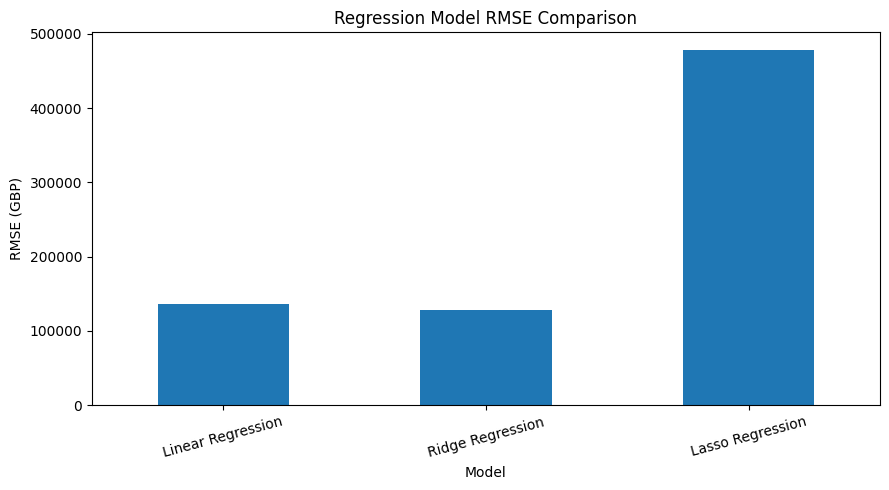

In [5]:
comparison.plot(
    x="Model",
    y="RMSE",
    kind="bar",
    legend=False,
    figsize=(9, 5),
    title="Regression Model RMSE Comparison"
)

plt.ylabel("RMSE (GBP)")
plt.xticks(rotation=15)
plt.tight_layout()
plt.savefig("model_rmse_comparison.png", dpi=200)
plt.show()